In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import kagglehub

# 1. Dataset download path lena
path = kagglehub.dataset_download("spscientist/students-performance-in-exams")
csv_file = f"{path}/StudentsPerformance.csv"

# 2. Data load karein
df = pd.read_csv(csv_file)
print("Data loaded successfully! Pehle 5 rows:")
display(df.head())

# 3. Features aur Target set karna
X = df.drop('math score', axis=1)
y = df['math score']

# 4. Text columns ko 0 aur 1 me badalna (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 5. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# 6. Linear Regression Model Train karna
model = LinearRegression()
model.fit(X_train, y_train)

# 7. Predictions & Evaluation
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- Model Performance ---")
print(f"R2 Score: {r2:.4f}")
print(f"Average Error (RMSE): {rmse:.2f} marks")

# 8. Comparison (Actual vs Predicted)
comparison = pd.DataFrame({
    'Actual Math Score': y_test.values[:5],
    'Predicted Math Score': np.round(y_pred[:5], 1)
})
print("\nSample Predictions:")
display(comparison)

Data loaded successfully! Pehle 5 rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- Model Performance ---
R2 Score: 0.8804
Average Error (RMSE): 5.39 marks

Sample Predictions:


,Actual Math Score,Predicted Math Score
0,91,76.4
1,53,58.9
2,80,77.0
3,74,76.9
4,84,87.6


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import kagglehub

# 1. Dataset download path lena
path = kagglehub.dataset_download("spscientist/students-performance-in-exams")
csv_file = f"{path}/StudentsPerformance.csv"

# 2. Data load karein
df = pd.read_csv(csv_file)
print("Data loaded successfully! Pehle 5 rows:")
display(df.head())

# 3. Features aur Target set karna
X = df.drop('math score', axis=1)
y = df['math score']

# 4. Text columns ko 0 aur 1 me badalna (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 5. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# 6. Linear Regression Model Train karna
model = LinearRegression()
model.fit(X_train, y_train)

# 7. Predictions & Evaluation
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- Model Performance ---")
print(f"R2 Score: {r2:.4f}")
print(f"Average Error (RMSE): {rmse:.2f} marks")

# 8. Comparison (Actual vs Predicted)
comparison = pd.DataFrame({
    'Actual Math Score': y_test.values[:5],
    'Predicted Math Score': np.round(y_pred[:5], 1)
})
print("\nSample Predictions:")
display(comparison)

Data loaded successfully! Pehle 5 rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- Model Performance ---
R2 Score: 0.8804
Average Error (RMSE): 5.39 marks

Sample Predictions:


,Actual Math Score,Predicted Math Score
0,91,76.4
1,53,58.9
2,80,77.0
3,74,76.9
4,84,87.6


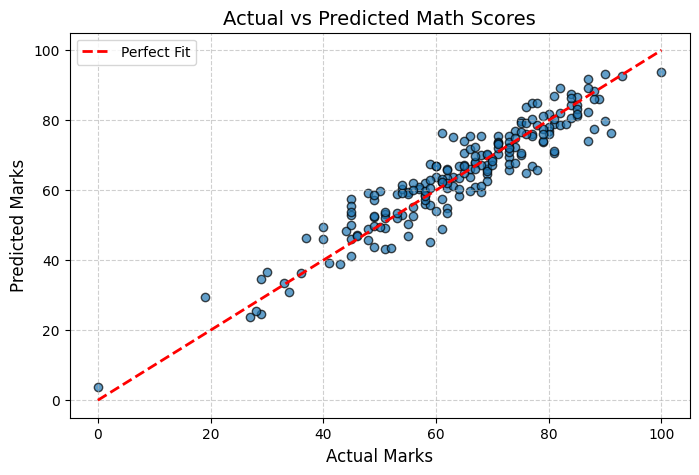

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Actual vs Predicted scatter points
plt.scatter(y_test, y_pred, color='#1f77b4', edgecolors='k', alpha=0.7)

# Perfect prediction line (Ideal 45-degree reference line)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2, label='Perfect Fit')

plt.title('Actual vs Predicted Math Scores', fontsize=14)
plt.xlabel('Actual Marks', fontsize=12)
plt.ylabel('Predicted Marks', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()